# Промежуточная аттестация 2 — RemI AI

## 1. Задача

Студент затруднился с темой. RemI AI задаёт начальные вопросы и может предложить дополнительно проверить связанный навык. Исследуем, можно ли по первым ответам предположить, что повторная проверка навыка даст результат, требующий внимания.

**Данные учебные:** все 106 участников — вымышленные тестовые профили. Диагностики относятся к тестовым сценариям; вопросы и допуска для учебного стенда имитировались. Наблюдения не являются репрезентативной выборкой настоящих студентов, а повторная проверка не является независимой экспертной оценкой. Результаты отражают поведение тестовых сценариев и не доказывают эффективность RemI AI.

Одна строка — первый подходящий повторный тест одного участника. До начала повторной проверки учитываются только автоматически оценённые начальные ответы той же темы. В итог входят два верных ответа из двух или не меньше двух из трёх. Две ошибки из двух или меньше двух верных из трёх — признак затруднения. Смешанный результат одного верного из двух исключён: для него нужна дополнительная проверка. Такой порог — учебное правило, а не утверждённая экспертом оценка знаний.

Результат анализа — предложение продолжить проверку, а не окончательное решение о знаниях или автоматическое назначение маршрута. Нейросетевой пример в конце посвящён отдельной задаче: подбору подходящего раздела по тексту запроса.

## 2. Библиотеки и данные

Для запуска понадобятся Python 3.10+, pandas, numpy, matplotlib, scikit-learn, onnxruntime и tokenizers. Рядом с блокнотом должны находиться файлы `student_cases.csv`, `catalog.csv`, `catalog_vectors.npy` и `neural_questions.json`. Данные не содержат имён, адресов, паролей или исходных идентификаторов студентов.

In [1]:
from pathlib import Path
import json
import math
import os
import re
from io import BytesIO
from collections import Counter

import onnxruntime as ort
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
def show_plot(fig):
    buffer=BytesIO()
    fig.savefig(buffer,format='png',dpi=130,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

data = pd.read_csv('student_cases.csv')
print('Строк:', len(data))
display(data.head())
print('Пропуски по столбцам:')
display(data.isna().sum().to_frame('пропусков'))

Строк: 106


,case_id,same_count,same_correct,other_count,other_correct,needs_review
0,1,2,0,16,6,1
1,2,2,0,6,6,0
2,3,2,0,6,6,0
3,4,2,0,4,4,0
4,5,3,1,10,4,1


Пропуски по столбцам:


,пропусков
case_id,0
same_count,0
same_correct,0
other_count,0
other_correct,0
needs_review,0


### Какие переменные рассматриваем

- `same_count`, `same_correct` — число начальных вопросов и правильных ответов по повторно проверяемому навыку.
- `other_count`, `other_correct` — число начальных вопросов и правильных ответов по другим навыкам той же выбранной темы.
- `needs_review` — результат последующей проверки: 1 — затруднение по учебному правилу, 0 — достаточно правильных ответов.
- `case_id` — случайный номер строки в обезличенной выгрузке, модель его не использует.

В модель не передаются ни результаты повторных вопросов, ни их текст, ни идентификаторы учащегося. Первая подходящая повторная проверка выбиралась отдельно для каждого тестового студента.

In [2]:
assert data.case_id.is_unique
assert data.needs_review.isin([0, 1]).all()
assert data[['same_count','same_correct','other_count','other_correct','needs_review']].notna().all().all()
assert (data.same_correct <= data.same_count).all()
assert (data.other_correct <= data.other_count).all()
print('Количество по классам:', data.needs_review.value_counts().sort_index().to_dict())
print('Повторов набора признаков:', data.drop(columns=['case_id','needs_review']).duplicated().sum())
print('Разных сочетаний признаков:', len(data.drop(columns=['case_id','needs_review']).drop_duplicates()))

Количество по классам: {0: 74, 1: 32}
Повторов набора признаков: 66
Разных сочетаний признаков: 40


Повторяющиеся сочетания признаков сохраняем: это разные вымышленные студенты, а не автоматически ошибки. Но большое число похожих тестовых сценариев может завышать качество при случайном разделении. В реальном исследовании нужно проверять модель на новых студентах и новых сценариях.

## 3. Деление на три части

60% — обучение, 20% — оценка и сравнение моделей, 20% — имитация будущих данных. Для сохранения долей классов используется стратификация; из-за округления число строк может отличаться на одну. Для прогнозной части целевая переменная удаляется, метрики на ней не считаются. Поскольку в исходном учебном снимке ответы известны, их скрытие имитирует практический сценарий.

Модель и набор признаков выбираются по трёхкратной проверке **внутри обучающей части**. Затем все модели сравниваются на первой части из 20%; если менять выбор по этой таблице, она уже не будет независимой итоговой проверкой.

In [3]:
train, temporary = train_test_split(data, test_size=0.4, random_state=SEED, stratify=data['needs_review'])
validation, future = train_test_split(temporary, test_size=0.5, random_state=SEED, stratify=temporary['needs_review'])
future_features = future.drop(columns=['needs_review']).copy()
del future, temporary
print('Обучение:', len(train), '| оценка:', len(validation), '| прогноз без ответов:', len(future_features))
print('Классы на обучении:', train.needs_review.value_counts().sort_index().to_dict())
future_features.to_csv('forecast_input.csv', index=False, encoding='utf-8-sig')

Обучение: 63 | оценка: 21 | прогноз без ответов: 22
Классы на обучении: {0: 44, 1: 19}


## 4. Разведочный анализ и очистка

Для анализа связей и выбора модели используем только обучающую часть. Проверяем допустимые значения до расчётов. Отсутствие ответов по другим навыкам (`other_count = 0`) оставляем: оно означает, что такие вопросы не задавались, а не пропущенные данные. Редкие допустимые результаты не удаляем. Для модели с расстояниями и логистической регрессии масштабирование обучается только внутри обучающих блоков.

Краткое описание обучающей части:


,same_count,same_correct,other_count,other_correct,needs_review
count,63.00,63.00,63.00,63.00,63.00
mean,2.19,0.51,7.06,3.86,0.30
std,0.40,0.76,5.65,2.02,0.46
min,2.00,0.00,0.00,0.00,0.00
25%,2.00,0.00,2.00,2.00,0.00
50%,2.00,0.00,6.00,4.00,0.00
75%,2.00,1.00,11.50,6.00,1.00
max,3.00,2.00,18.00,7.00,1.00


Результат повторной проверки по первым ответам на тот же навык:


needs_review,0,1,All
same_correct,,,
0,33,8,41
1,1,11,12
2,10,0,10
All,44,19,63


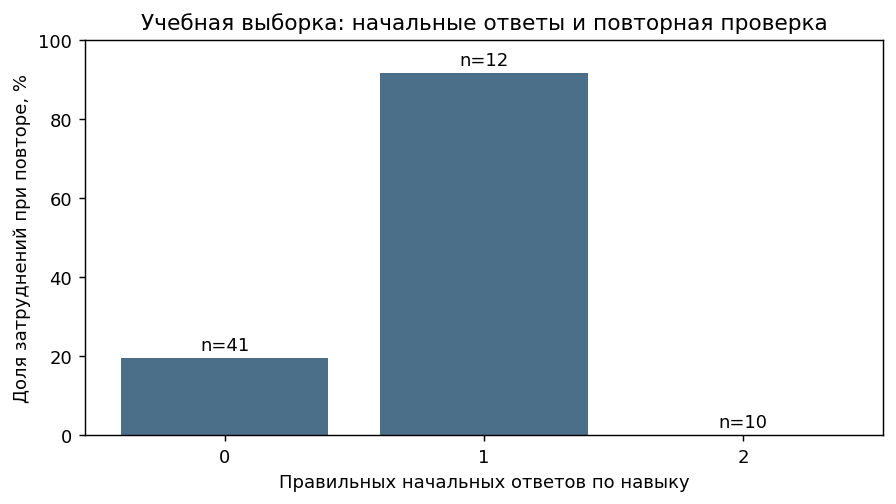

In [4]:
assert train[['same_count','same_correct','other_count','other_correct','needs_review']].notna().all().all()
assert (train[['same_count','same_correct','other_count','other_correct']] >= 0).all().all()
print('Краткое описание обучающей части:')
display(train.drop(columns='case_id').describe().round(2))
print('Результат повторной проверки по первым ответам на тот же навык:')
display(pd.crosstab(train.same_correct, train.needs_review, margins=True))
fig, ax = plt.subplots(figsize=(7,4))
group = train.groupby('same_correct').needs_review.agg(['mean','count'])
ax.bar(group.index.astype(str), group['mean'] * 100, color='#4c6f89')
ax.set(xlabel='Правильных начальных ответов по навыку', ylabel='Доля затруднений при повторе, %', title='Учебная выборка: начальные ответы и повторная проверка', ylim=(0,100))
for i, row in enumerate(group.itertuples()):
    ax.text(i, min(98, row.mean*100+2), f'n={int(row.count)}', ha='center')
plt.tight_layout(); show_plot(fig)

## 5. Сравнение моделей

Сравним простую модель большинства, логистическую регрессию, дерево решений, случайный лес и метод ближайших соседей. Для каждого алгоритма проверим два набора признаков. Основная метрика для выбора — F1 класса «требует внимания»: она учитывает и пропущенные затруднения, и лишние предложения проверки. Также покажем полноту, точность и матрицу ошибок. Чем больше пропущенных случаев, тем чаще студенту не предложат уточнить сложную тему.

Количество студентов небольшое, многие сценарии похожи. Даже корректное разделение по студентам не делает эти результаты оценкой поведения реальных людей.

In [5]:
simple = ['same_count','same_correct']
expanded = simple + ['other_count','other_correct']
feature_sets = {'только навык': simple, 'навык и другие ответы': expanded}
models = {
    'Базовая': DummyClassifier(strategy='most_frequent'),
    'Логистическая регрессия': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    'Дерево решений': DecisionTreeClassifier(max_depth=3, min_samples_leaf=4, random_state=SEED),
    'Случайный лес': RandomForestClassifier(n_estimators=100, max_depth=4, min_samples_leaf=3, random_state=SEED, n_jobs=1),
    'Ближайшие соседи': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
items=[]
for feat_name, features in feature_sets.items():
    for name, model in models.items():
        scores = cross_val_score(model, train[features], train.needs_review, cv=cv, scoring='f1', n_jobs=1)
        items.append({'признаки':feat_name, 'модель':name, 'CV F1 среднее':scores.mean(), 'CV F1 разброс':scores.std()})
cv_table=pd.DataFrame(items).sort_values('CV F1 среднее', ascending=False).reset_index(drop=True)
display(cv_table.round(3))
chosen=cv_table[cv_table['модель']!='Базовая'].iloc[0]
chosen_name=chosen['модель']; chosen_features=feature_sets[chosen['признаки']]
print('Выбрано по CV на обучении:', chosen_name, '| признаки:', chosen['признаки'])

,признаки,модель,CV F1 среднее,CV F1 разброс
0,навык и другие ответы,Ближайшие соседи,0.880,0.022
1,навык и другие ответы,Логистическая регрессия,0.872,0.031
2,навык и другие ответы,Случайный лес,0.863,0.035
3,навык и другие ответы,Дерево решений,0.730,0.090
4,только навык,Логистическая регрессия,0.701,0.048
5,только навык,Дерево решений,0.701,0.048
6,только навык,Случайный лес,0.701,0.048
7,только навык,Ближайшие соседи,0.669,0.081
8,только навык,Базовая,0.000,0.000
9,навык и другие ответы,Базовая,0.000,0.000


Выбрано по CV на обучении: Ближайшие соседи | признаки: навык и другие ответы


,признаки,модель,accuracy,precision,recall,F1,ROC-AUC
0,только навык,Базовая,0.714,0.000,0.000,0.000,0.500
1,только навык,Логистическая регрессия,0.714,0.500,0.333,0.400,0.667
2,только навык,Дерево решений,0.714,0.500,0.333,0.400,0.667
3,только навык,Случайный лес,0.714,0.500,0.333,0.400,0.667
4,только навык,Ближайшие соседи,0.714,0.500,0.333,0.400,0.667
5,навык и другие ответы,Базовая,0.714,0.000,0.000,0.000,0.500
6,навык и другие ответы,Логистическая регрессия,0.810,0.667,0.667,0.667,0.889
7,навык и другие ответы,Дерево решений,0.810,0.667,0.667,0.667,0.889
8,навык и другие ответы,Случайный лес,0.857,0.714,0.833,0.769,0.889
9,навык и другие ответы,Ближайшие соседи,0.857,0.714,0.833,0.769,0.933


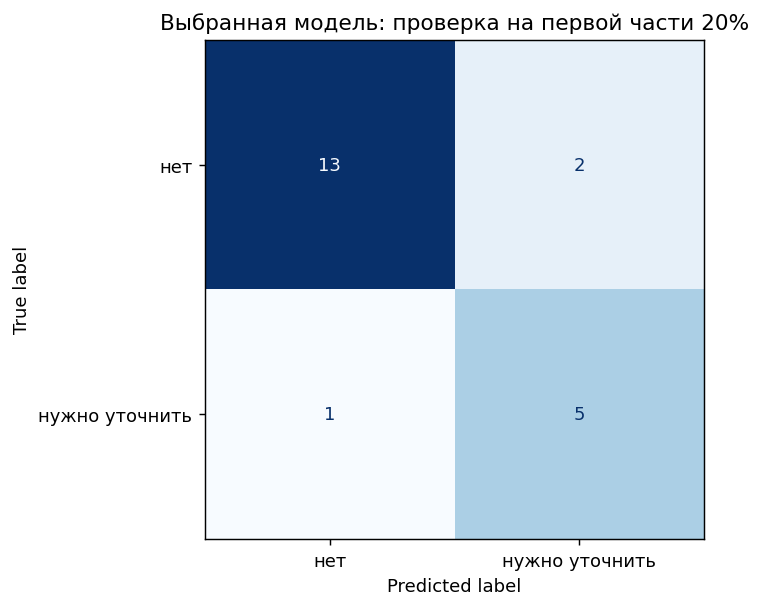

Матрица: строки — фактический класс, столбцы — прогноз. Ошибки нижняя левая ячейка — пропущенные затруднения.


In [6]:
from sklearn.base import clone
evaluations=[]
for feat_name, features in feature_sets.items():
    for name, model in models.items():
        fitted=clone(model).fit(train[features],train.needs_review)
        predicted=fitted.predict(validation[features])
        probability=fitted.predict_proba(validation[features])[:,1]
        evaluations.append({'признаки':feat_name, 'модель':name,
            'accuracy':accuracy_score(validation.needs_review,predicted),
            'precision':precision_score(validation.needs_review,predicted,zero_division=0),
            'recall':recall_score(validation.needs_review,predicted,zero_division=0),
            'F1':f1_score(validation.needs_review,predicted,zero_division=0),
            'ROC-AUC':roc_auc_score(validation.needs_review,probability)})
validation_table=pd.DataFrame(evaluations)
display(validation_table.round(3))
selected_model=clone(models[chosen_name]).fit(train[chosen_features],train.needs_review)
selected_pred=selected_model.predict(validation[chosen_features])
matrix=confusion_matrix(validation.needs_review,selected_pred,labels=[0,1])
chart=ConfusionMatrixDisplay(matrix,display_labels=['нет','нужно уточнить']).plot(cmap='Blues',colorbar=False)
plt.title('Выбранная модель: проверка на первой части 20%');plt.tight_layout();show_plot(chart.figure_)
print('Матрица: строки — фактический класс, столбцы — прогноз. Ошибки нижняя левая ячейка — пропущенные затруднения.')

## 6. Прогноз для новых случаев

Используем модель, выбранную внутри обучающей части. В `predictions.csv` сохраняются условный номер случая, оценка модели и предложение следующего шага. Метки для этих строк не раскрываются и качество по ним не считается. Значение модели не является проверенной вероятностью для настоящего студента.

In [7]:
proba=selected_model.predict_proba(future_features[chosen_features])[:,1]
labels=selected_model.predict(future_features[chosen_features])
predictions=pd.DataFrame({'case_id':future_features.case_id.to_numpy(), 'оценка_модели':np.round(proba,3),
    'предположение':np.where(labels==1,'Предложить дополнительную проверку навыка','Продолжить диагностику по правилам')})
predictions.to_csv('predictions.csv',index=False,encoding='utf-8-sig')
print('Получено прогнозов:',len(predictions))
display(predictions.head(10))

Получено прогнозов: 22


,case_id,оценка_модели,предположение
0,92,0.0,Продолжить диагностику по правилам
1,38,0.0,Продолжить диагностику по правилам
2,84,0.8,Предложить дополнительную проверку навыка
3,4,0.0,Продолжить диагностику по правилам
4,72,0.0,Продолжить диагностику по правилам
5,35,0.8,Предложить дополнительную проверку навыка
6,19,0.8,Предложить дополнительную проверку навыка
7,3,0.0,Продолжить диагностику по правилам
8,86,1.0,Предложить дополнительную проверку навыка
9,89,0.8,Предложить дополнительную проверку навыка


## 7. Отдельная задача для нейросети: подобрать материал по запросу

Студент описывает затруднение словами, а система ищет подходящий учебный раздел. Используем уже обученную мультиязычную модель MiniLM: она превращает текст в вектор чисел; похожесть векторов помогает сортировать разделы. Мы **не обучаем** нейросеть на этих 27 примерах.

В учебной проверке есть 26 разделов и 27 заранее размеченных запросов. Сравним нейросеть с простым поиском по словам. Hit@1 — доля запросов, для которых подходящий раздел оказался первым; MRR учитывает, на каком месте оказался первый подходящий раздел. Список очень мал и подготовлен для тестирования проекта, поэтому это не оценка пользы для настоящих студентов. Для честного сравнения рассматривается весь набор разделов; в сайте действуют дополнительные фильтры навыка и допуска.

Для первого запуска нейросетевой части нужны локальные файлы модели. Если они отсутствуют, следующая ячейка скачает их при наличии интернета и проверит контрольные суммы. Можно вместо этого указать папку с уже имеющимися файлами через переменную среды `REMI_MODEL_DIR`. Размер модели — около 118 МБ.

In [8]:
import hashlib
import urllib.request
from tokenizers import Tokenizer
import onnxruntime as ort

model_dir=Path(os.getenv('REMI_MODEL_DIR','models/minilm'))
files={'tokenizer.json':('tokenizer.json','b60b6b43406a48bf3638526314f3d232d97058bc93472ff2de930d43686fa441'),
       'model_quantized.onnx':('onnx/model_quantized.onnx','66fc00f5f29afcaff34092e1bdd20008ca3918265a82fb9695a551e510cc4ebc')}
def sha256(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''): h.update(block)
    return h.hexdigest()
revision='2c4055b12046f11709e9df2c122e59ffbdc2f900'
for local,(remote,expected) in files.items():
    destination=model_dir/local
    if not destination.exists():
        destination.parent.mkdir(parents=True,exist_ok=True)
        url=f'https://huggingface.co/Xenova/paraphrase-multilingual-MiniLM-L12-v2/resolve/{revision}/{remote}'
        with urllib.request.urlopen(url,timeout=120) as response, destination.open('wb') as output:
            while True:
                block=response.read(1024*1024)
                if not block: break
                output.write(block)
    if sha256(destination)!=expected: raise ValueError(f'Не совпадает контрольная сумма: {local}')
tokenizer=Tokenizer.from_file(str(model_dir/'tokenizer.json'))
tokenizer.enable_truncation(max_length=128)
options=ort.SessionOptions();options.intra_op_num_threads=2
session=ort.InferenceSession(str(model_dir/'model_quantized.onnx'),options,providers=['CPUExecutionProvider'])
def encode(text):
    tok=tokenizer.encode(text)
    raw={'input_ids':tok.ids,'attention_mask':tok.attention_mask,'token_type_ids':tok.type_ids}
    batch={i.name:np.asarray([raw[i.name]],dtype=np.int64) for i in session.get_inputs()}
    hidden=session.run(None,batch)[0][0]
    v=hidden[np.asarray(tok.attention_mask,dtype=bool)].mean(axis=0)
    return v/np.linalg.norm(v)
print('Модель готова')

Модель готова


In [9]:
catalog=pd.read_csv('catalog.csv').fillna('')
vectors=np.load('catalog_vectors.npy')
questions=json.loads(Path('neural_questions.json').read_text(encoding='utf-8'))
assert len(catalog)==len(vectors)
titles=catalog.title.tolist()
def words(text): return Counter(re.findall(r'[а-яёa-z0-9]+',text.casefold()))
documents=[words(t+' '+d) for t,d in zip(catalog.title,catalog.description)]
def weights(bag):
    return {t:n*(1+math.log((1+len(documents))/(1+sum(t in doc for doc in documents)))) for t,n in bag.items()}
def lexical(q,doc):
    a=weights(q); b=weights(doc)
    norm=math.sqrt(sum(v*v for v in a.values())*sum(v*v for v in b.values()))
    return sum(v*b.get(t,0) for t,v in a.items())/norm if norm else 0
records=[]
for item in questions:
    expected=set(item['expected']); assert expected.issubset(set(titles))
    ranks={}
    for method, scores in [('MiniLM',vectors@encode(item['query'])),('По словам',[lexical(words(item['query']),d) for d in documents])]:
        order=np.argsort(-np.asarray(scores),kind='stable')
        rank=next(i for i,idx in enumerate(order,1) if titles[idx] in expected)
        ranks[method]=rank
    records.append({'Запрос':item['query'],'MiniLM':ranks['MiniLM'],'По словам':ranks['По словам']})
ranks=pd.DataFrame(records)
for method in ['MiniLM','По словам']:
    print(method,'первый подходящий:',int((ranks[method]==1).sum()),'из',len(ranks),'| MRR:',round((1/ranks[method]).mean(),3))
display(ranks.head(8))

MiniLM первый подходящий: 20 из 27 | MRR: 0.8
По словам первый подходящий: 14 из 27 | MRR: 0.65


,Запрос,MiniLM,По словам
0,"Как узнать знак рассогласования, если фактичес...",5,2
1,Что подаётся на вход регулятора при вычитании ...,1,1
2,Как отличить нагрев по расписанию от термостата?,1,1
3,Полив включается на пять минут. Замкнут ли так...,1,1
4,Как дифференцировать несколько слагаемых с пос...,1,3
5,Найти наклон касательной к графику полинома в ...,4,2
6,К чему приближается частное при стремлении арг...,1,5
7,Как вычислять пределы функций подстановкой?,1,1


## 8. Выводы

В работе рассмотрены первичные ответы и результаты отдельной повторной проверки, разделены данные, сравнены несколько классических моделей и подготовлены прогнозы. Дополнительно использована заранее обученная нейросеть для поиска разделов по тексту.

Полученные цифры относятся к небольшому набору вымышленных тестовых сценариев. Похожие сценарии повторяются, а оценки выставлялись автоматически; результаты нельзя переносить на настоящих студентов или считать подтверждением пользы рекомендаций. Для дальнейшей работы нужны проверенные задания и согласованная разметка, достаточно разнообразные данные, отдельная оценка на новых участниках и сравнение с простыми правилами. Нейросетевой подбор также требует предметной проверки.